# 07b. Performance against each parameter (Optuna's built-in plots)

Loads each region's saved study (`<REGION>_study.db`, written by notebook 07) and draws Optuna's own plots, so nothing is refitted. Macro-F1 is objective 0 of the two-objective study, so every plot is given `target=lambda t: t.values[0]`; set `OBJECTIVE = 1` to see the same plots for complexity.

- **Slice plot:** the objective against each parameter, one panel per parameter, points coloured by trial number (later trials are darker).
- **Parameter importance:** Optuna's estimate of how much each parameter matters for the objective.
- **Optimization history:** the objective per trial, with the best so far.

**Read these plots with care: they are biased toward combinations that worked.** The first 15 trials are random, but after that the TPE sampler concentrates on regions that looked promising and rarely visits the rest, unlike a grid search. A parameter can therefore look useful in a slice only because it was usually sampled together with other settings that helped. For example, more trees can show higher F1 simply because high tree counts were tried alongside many bands or many samples, not because trees help on their own. The importance plot is built from the same sampled trials and has the same limitation.

Use these plots to see where the sampler spent its trials and what the best region looks like. To attribute an effect to one parameter, use the model-based knob effects in the report, or a controlled check that changes one setting at a time from a fixed baseline.

In [5]:
from pathlib import Path
import os
import optuna
import matplotlib.pyplot as plt
from optuna.visualization import plot_slice, plot_param_importances, plot_optimization_history

optuna.logging.set_verbosity(optuna.logging.WARNING)

CONFIG_DIR = Path('data/optuna_regional_gee_configs')   # where notebook 07 wrote <REGION>_study.db
# regions: REGIONS env var (comma separated), default all seven; or edit the list directly, e.g. ['HIM', 'PEN']
REGIONS = os.environ.get('REGIONS', 'HIM,PEN,DES,IGP,WGR,ICR,NEI').split(',')
OBJECTIVE = 0                                            # 0 = mean macro-F1, 1 = model complexity
NAME = ['Mean Macro-F1', 'Model Complexity'][OBJECTIVE]
target = lambda t: t.values[OBJECTIVE]
OUT_DIR = CONFIG_DIR / 'parameter_plots'
OUT_DIR.mkdir(parents=True, exist_ok=True)

def load(region):
    return optuna.load_study(study_name=f'rf_{region}', storage=f'sqlite:///{CONFIG_DIR / (region + "_study.db")}')

In [6]:
for region in REGIONS:
    study = load(region)
    n = sum(t.state.name == 'COMPLETE' for t in study.trials)
    fig = plot_slice(study, target=target, target_name=NAME)
    fig.update_layout(title=f'{NAME} against each parameter - {region} ({n} trials)')
    fig.write_html(OUT_DIR / f'{region}_slice.html')
    fig.show()

In [7]:
for region in REGIONS:
    study = load(region)
    fig = plot_param_importances(study, target=target, target_name=NAME)
    fig.update_layout(title=f'Parameter importance for {NAME} - {region}')
    fig.write_html(OUT_DIR / f'{region}_importance.html')
    fig.show()

In [8]:
for region in REGIONS:
    study = load(region)
    fig = plot_optimization_history(study, target=target, target_name=NAME)
    fig.update_layout(title=f'Optimization history ({NAME}) - {region}')
    fig.write_html(OUT_DIR / f'{region}_history.html')
    fig.show()

## Static versions for slides

The same three plots with Optuna's matplotlib backend. They are not interactive, so they can be copied straight into a slide deck, and each is also saved as a PNG (200 dpi) in `parameter_plots/`. The same caution applies: these are the sampled trials, not a controlled comparison.

/tmp/ipykernel_234677/2655312642.py:16: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_slice(study, target=target, target_name=NAME)
/tmp/ipykernel_234677/2655312642.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


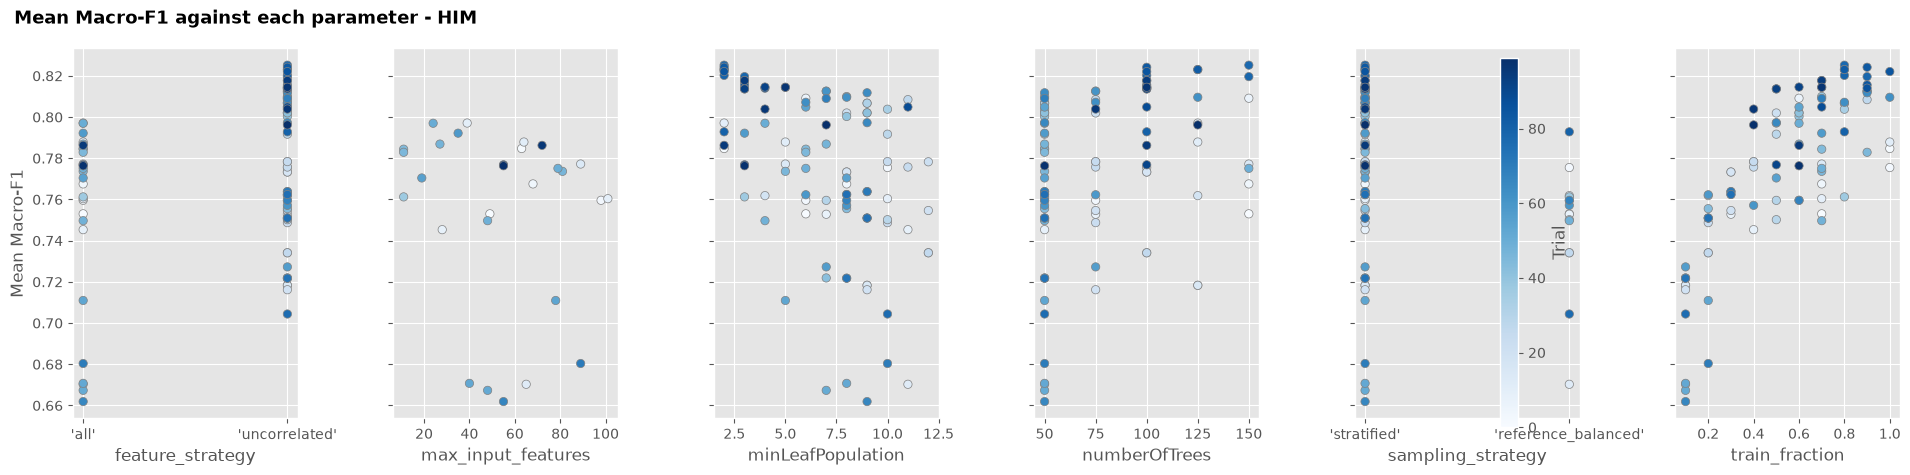

/tmp/ipykernel_234677/2655312642.py:18: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_importances(study, target=target, target_name=NAME)


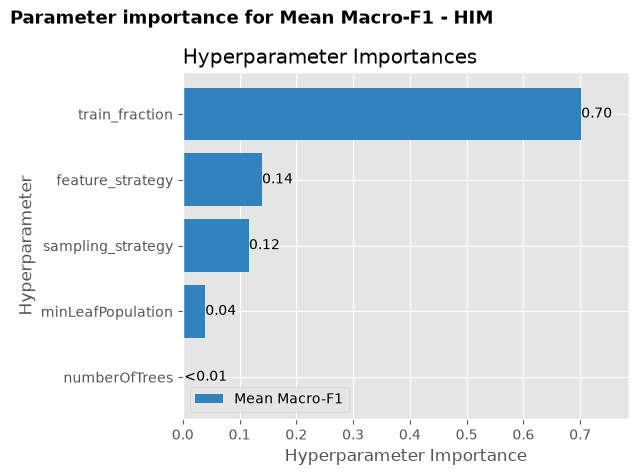

/tmp/ipykernel_234677/2655312642.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_history(study, target=target, target_name=NAME)


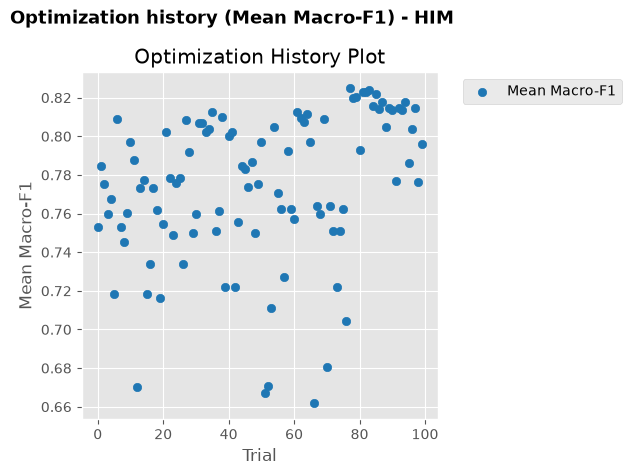

/tmp/ipykernel_234677/2655312642.py:16: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_slice(study, target=target, target_name=NAME)
/tmp/ipykernel_234677/2655312642.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


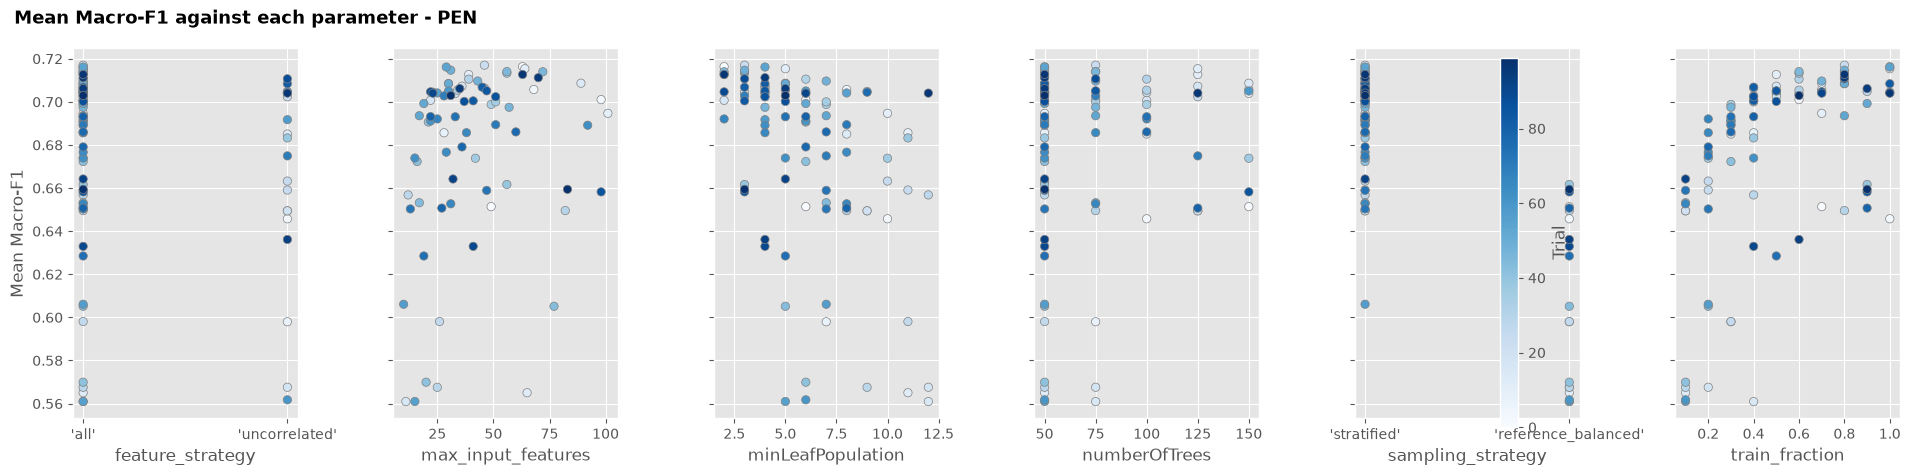

/tmp/ipykernel_234677/2655312642.py:18: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_importances(study, target=target, target_name=NAME)


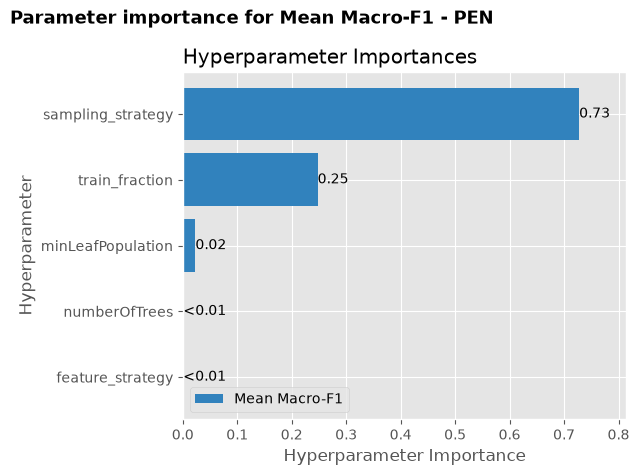

/tmp/ipykernel_234677/2655312642.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_history(study, target=target, target_name=NAME)


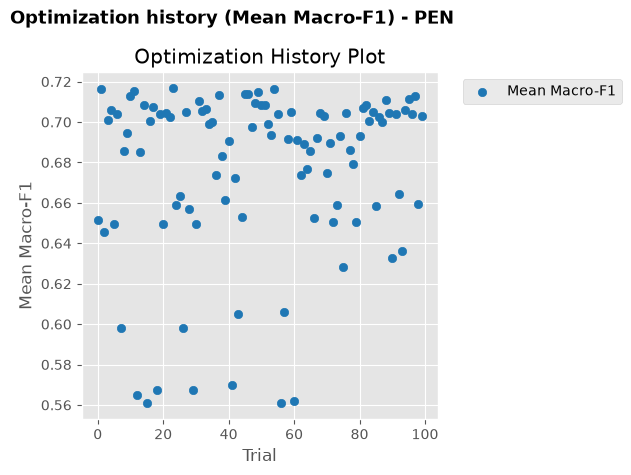

/tmp/ipykernel_234677/2655312642.py:16: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_slice(study, target=target, target_name=NAME)
/tmp/ipykernel_234677/2655312642.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


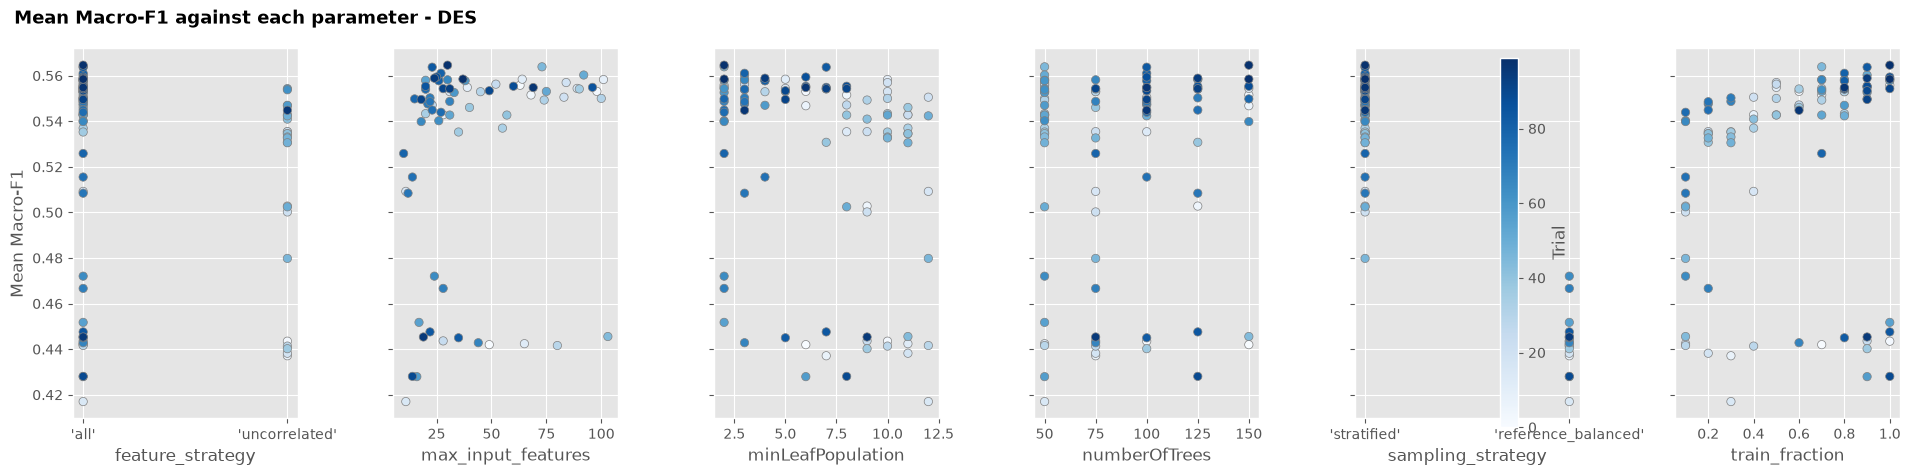

/tmp/ipykernel_234677/2655312642.py:18: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_importances(study, target=target, target_name=NAME)


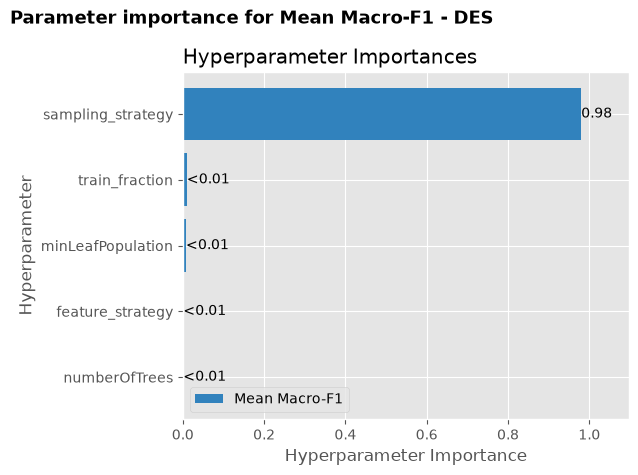

/tmp/ipykernel_234677/2655312642.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_history(study, target=target, target_name=NAME)


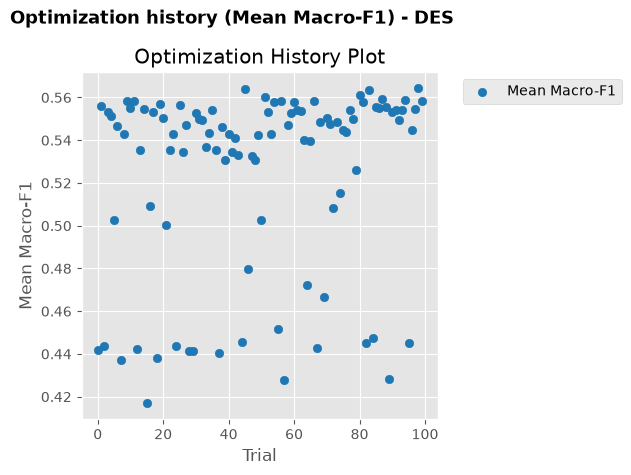

/tmp/ipykernel_234677/2655312642.py:16: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_slice(study, target=target, target_name=NAME)
/tmp/ipykernel_234677/2655312642.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


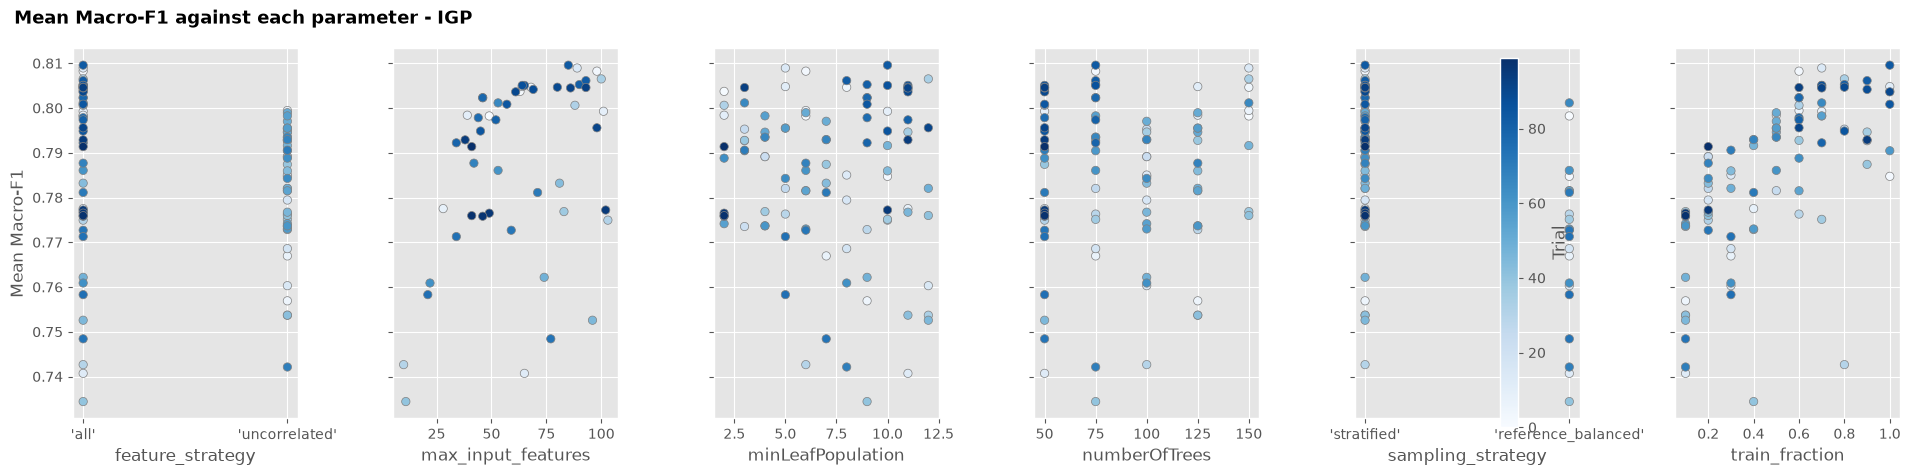

/tmp/ipykernel_234677/2655312642.py:18: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_importances(study, target=target, target_name=NAME)


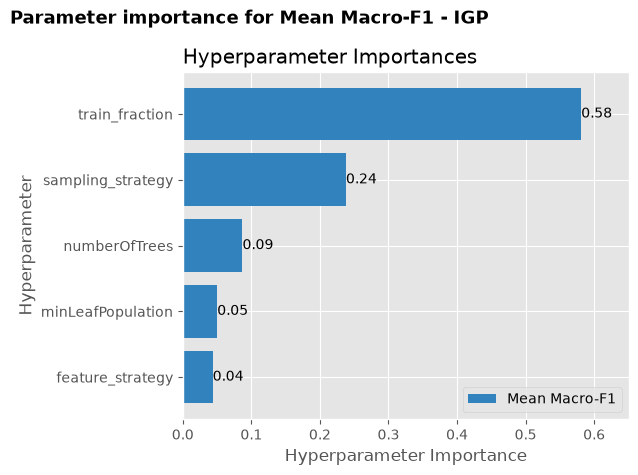

/tmp/ipykernel_234677/2655312642.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_history(study, target=target, target_name=NAME)


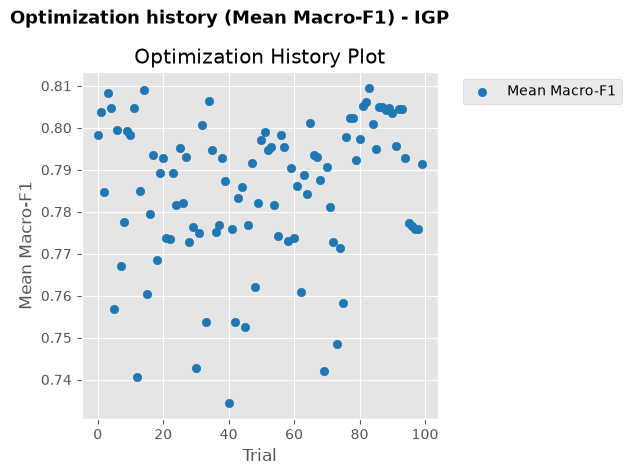

/tmp/ipykernel_234677/2655312642.py:16: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_slice(study, target=target, target_name=NAME)
/tmp/ipykernel_234677/2655312642.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


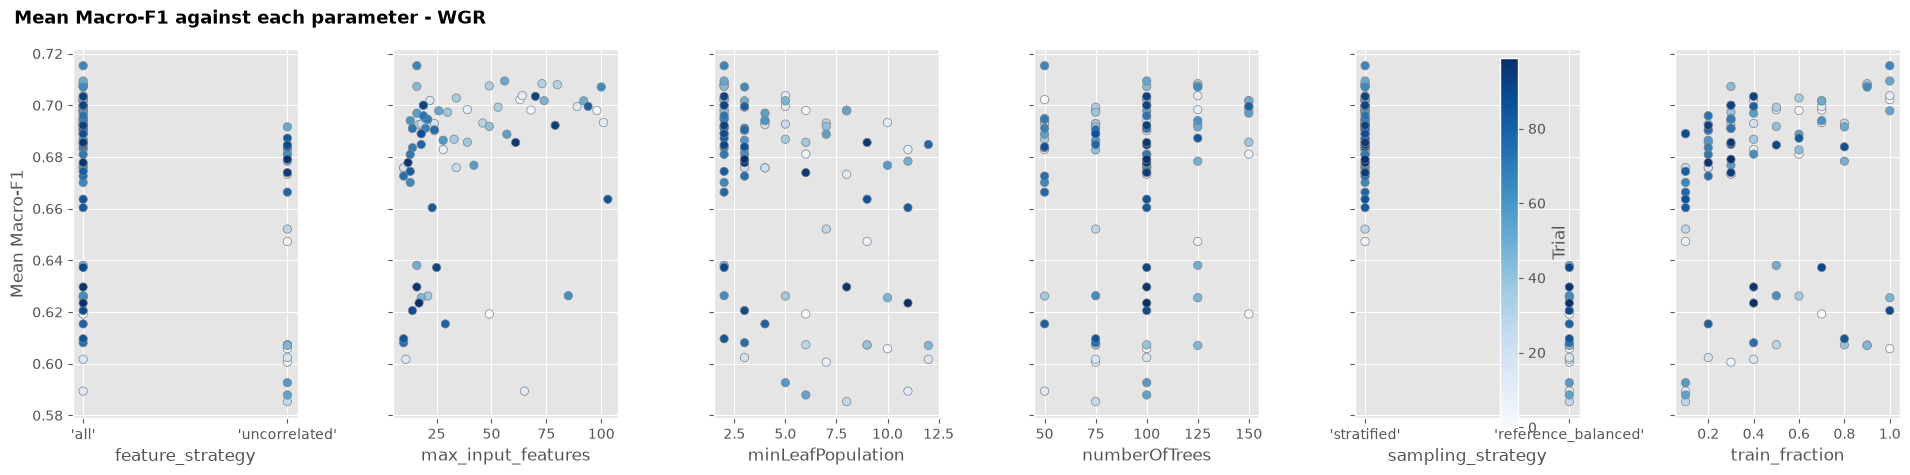

/tmp/ipykernel_234677/2655312642.py:18: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_importances(study, target=target, target_name=NAME)


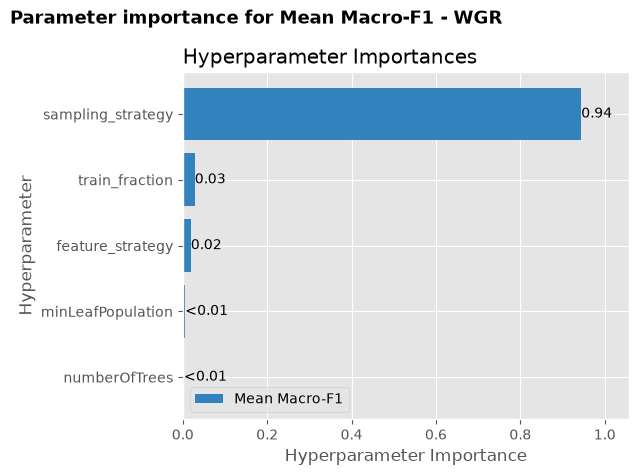

/tmp/ipykernel_234677/2655312642.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_history(study, target=target, target_name=NAME)


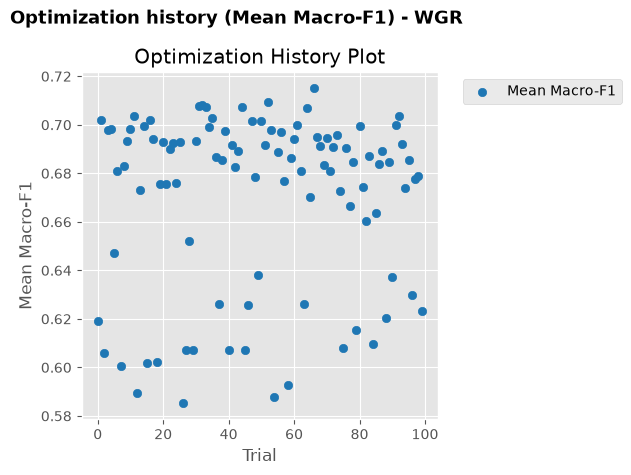

/tmp/ipykernel_234677/2655312642.py:16: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_slice(study, target=target, target_name=NAME)
/tmp/ipykernel_234677/2655312642.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


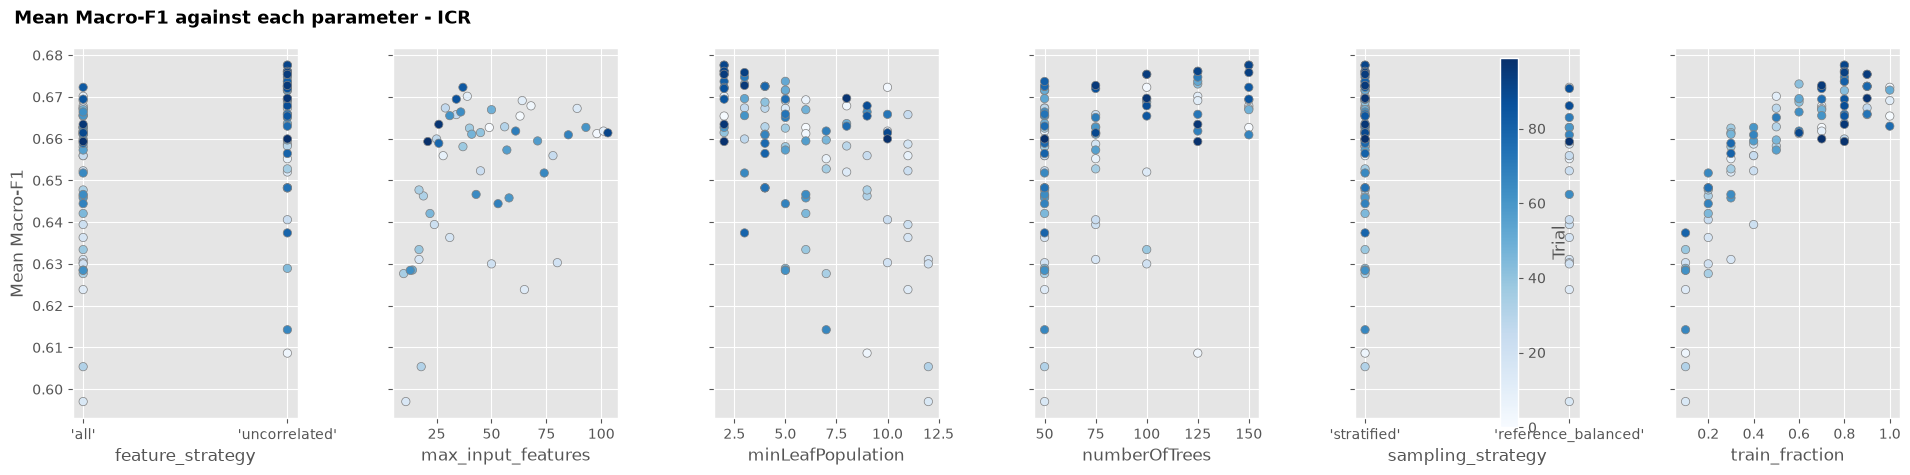

/tmp/ipykernel_234677/2655312642.py:18: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_importances(study, target=target, target_name=NAME)


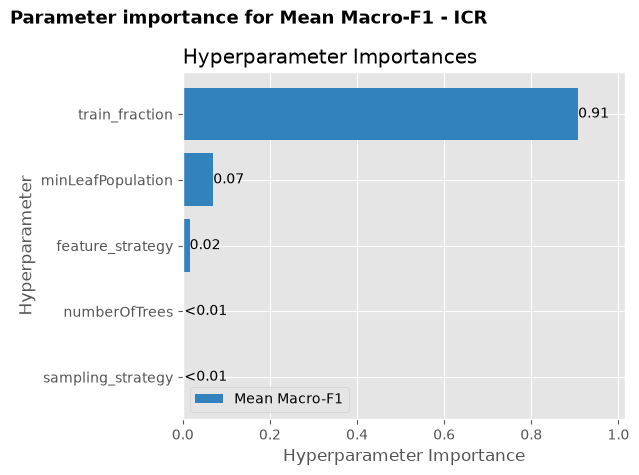

/tmp/ipykernel_234677/2655312642.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_history(study, target=target, target_name=NAME)


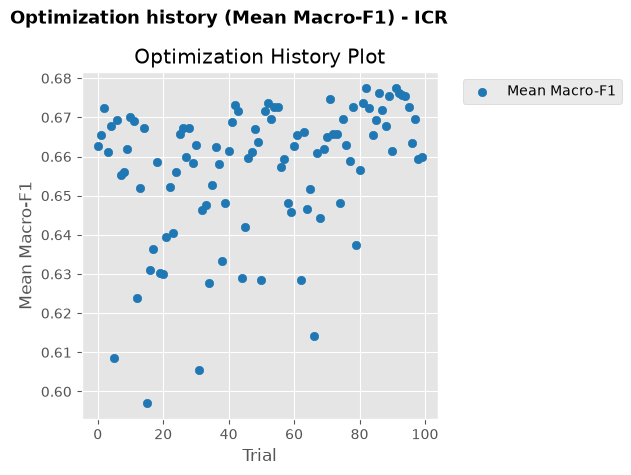

/tmp/ipykernel_234677/2655312642.py:16: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_slice(study, target=target, target_name=NAME)
/tmp/ipykernel_234677/2655312642.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


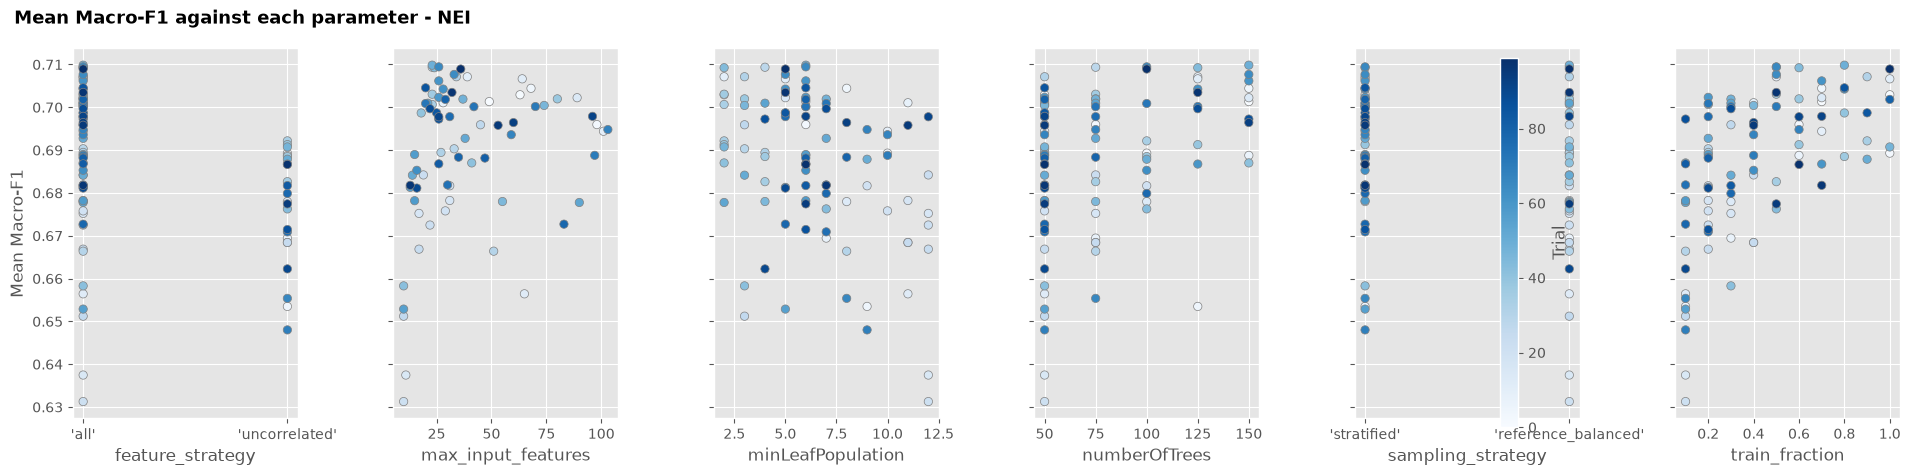

/tmp/ipykernel_234677/2655312642.py:18: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_importances(study, target=target, target_name=NAME)


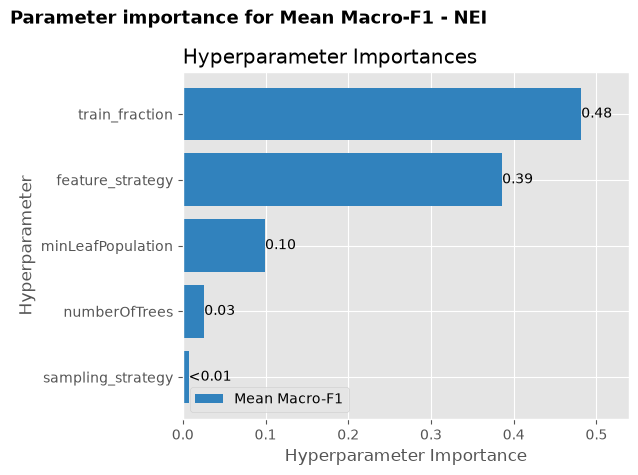

/tmp/ipykernel_234677/2655312642.py:20: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = mpl_history(study, target=target, target_name=NAME)


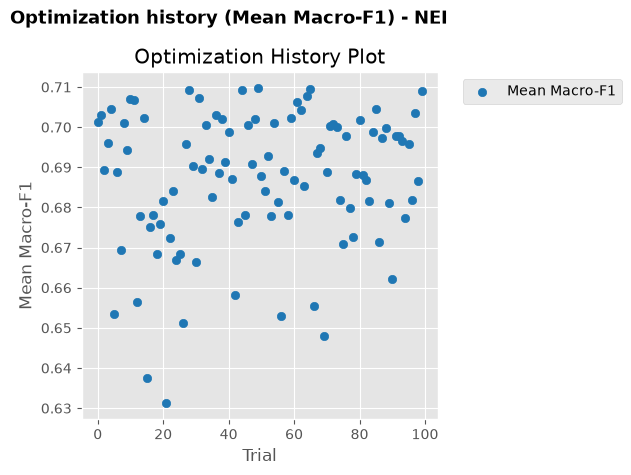

In [9]:
from optuna.visualization.matplotlib import (plot_slice as mpl_slice,
                                              plot_param_importances as mpl_importances,
                                              plot_optimization_history as mpl_history)

def save_static(ax_or_axes, region, name, title):
    import numpy as np
    axes = np.atleast_1d(ax_or_axes).ravel()
    fig = axes[0].figure
    fig.suptitle(title, x=0.01, ha='left', fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(OUT_DIR / f'{region}_{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

for region in REGIONS:
    study = load(region)
    ax = mpl_slice(study, target=target, target_name=NAME)
    save_static(ax, region, 'slice_static', f'{NAME} against each parameter - {region}')
    ax = mpl_importances(study, target=target, target_name=NAME)
    save_static(ax, region, 'importance_static', f'Parameter importance for {NAME} - {region}')
    ax = mpl_history(study, target=target, target_name=NAME)
    save_static(ax, region, 'history_static', f'Optimization history ({NAME}) - {region}')